# <b>Data Analysis Interview Challenge</b>

### <b>Part 1 ‐ Exploratory data analysis</b>

In [1]:
import pandas as pd

In [2]:
logins_pd = pd.read_json("logins.json")

In [3]:
logins_pd.head(10)

,login_time
0,1970-01-01 20:13:18
1,1970-01-01 20:16:10
2,1970-01-01 20:16:37
3,1970-01-01 20:16:36
4,1970-01-01 20:26:21
5,1970-01-01 20:21:41
6,1970-01-01 20:12:16
7,1970-01-01 20:35:47
8,1970-01-01 20:35:38
9,1970-01-01 20:47:52


In [4]:
logins_pd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93142 entries, 0 to 93141
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   login_time  93142 non-null  datetime64[ns]
dtypes: datetime64[ns](1)
memory usage: 727.8 KB


In [5]:
logins_pd = logins_pd.sort_values("login_time")

In [6]:
logins_pd.head(10)

,login_time
6,1970-01-01 20:12:16
0,1970-01-01 20:13:18
1,1970-01-01 20:16:10
3,1970-01-01 20:16:36
2,1970-01-01 20:16:37
5,1970-01-01 20:21:41
10,1970-01-01 20:26:05
4,1970-01-01 20:26:21
11,1970-01-01 20:31:03
12,1970-01-01 20:34:46


In [7]:
logins_pd = logins_pd.set_index("login_time")

In [8]:
logins_pd.head(5)

""
login_time
1970-01-01 20:12:16
1970-01-01 20:13:18
1970-01-01 20:16:10
1970-01-01 20:16:36
1970-01-01 20:16:37


In [9]:
# Count logins in each 15-minute interval
login_counts_15min = logins_pd.resample("15min").size()

In [10]:
login_counts_15min.head()

login_time
1970-01-01 20:00:00    2
1970-01-01 20:15:00    6
1970-01-01 20:30:00    9
1970-01-01 20:45:00    7
1970-01-01 21:00:00    1
Freq: 15min, dtype: int64

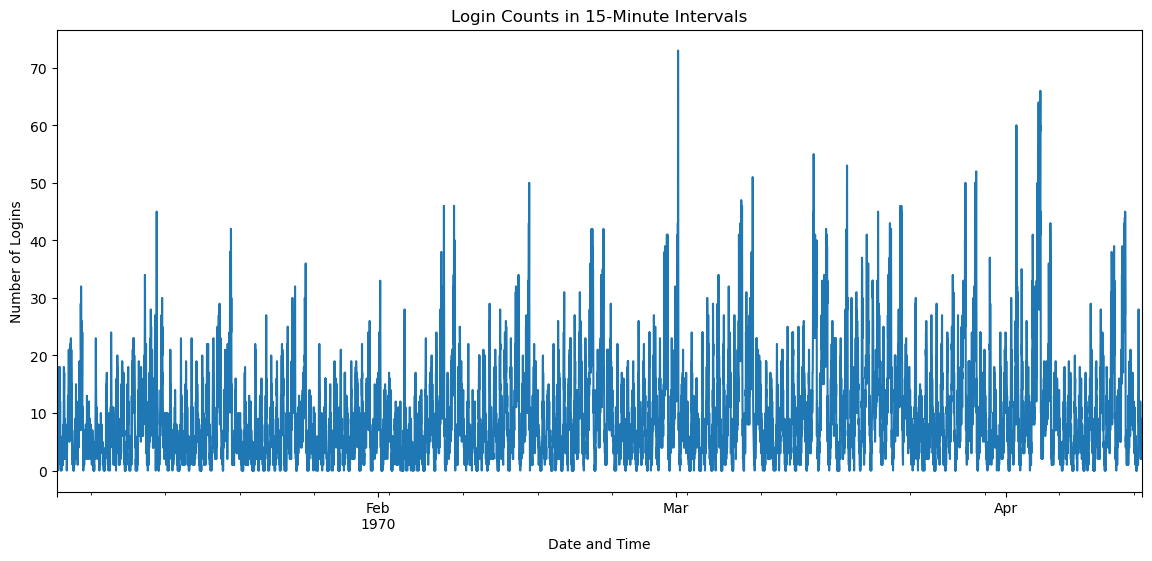

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

login_counts_15min.plot()

plt.title("Login Counts in 15-Minute Intervals")
plt.xlabel("Date and Time")
plt.ylabel("Number of Logins")

plt.show()

<b> Part 1 - EDA: Describe the resulting time series of login counts in ways that best characterize the underlying patterns of the demand</b>

<b>Answer:</b> Most of the login counts in 15-min intervals are below 10-15 logins. But, there are frequent short-lived spikes, like intervals reaching 30-50+ logins.  
There is a spike in early March that goes up to 70 logins. I would not consider this spike as an outliers without further investigation. 
Login activities seem to increase in March and April. However, the full plot is too dense to conclude confidently that there is an overall upward trend. 


In [12]:
daily_cycle = login_counts_15min.groupby(
    login_counts_15min.index.time
).mean()

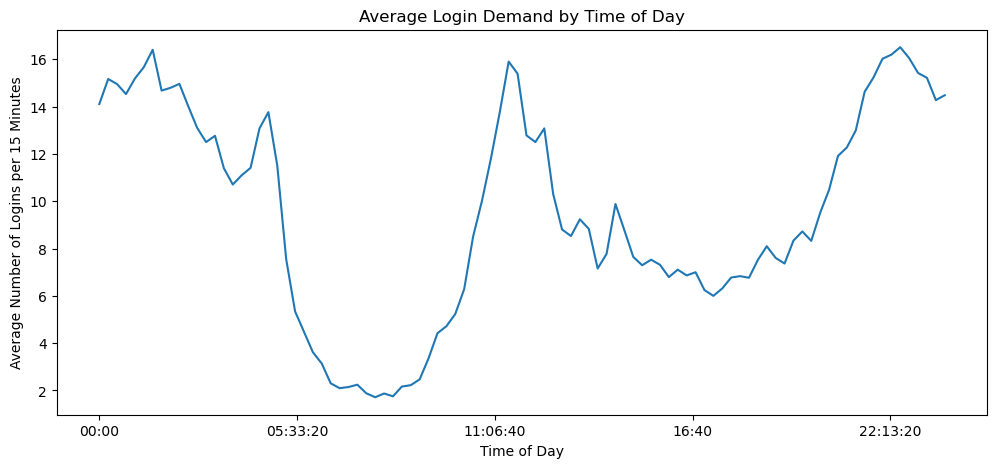

In [13]:
plt.figure(figsize=(12, 5))
daily_cycle.plot()

plt.title("Average Login Demand by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Average Number of Logins per 15 Minutes")
plt.show()

<b> Part 1 - EDA: Please report/illustrate important features of the demand, such as daily cycles.</b>

<b>Answer:</b> The daily cycles clearly shows the hightest and lowest demand time of the day. Highest login activities occur around 11:06, 22:13 and 02:00. 
Lowest login activity occurs around 08:00. Overall, the data suggest three periods of relatively high demand: late night/early morning, around noon, and late evening, with the strongest low-demand period occurring in the early morning.

----

# <b> Part 2 ‐ Experiment and metrics design</b>

The neighboring cities of Gotham and Metropolis have complementary circadian rhythms: on
weekdays, Ultimate Gotham is most active at night, and Ultimate Metropolis is most active
during the day. On weekends, there is reasonable activity in both cities.
However, a toll bridge, with a two way toll, between the two cities causes driver partners to tend
to be exclusive to each city. The Ultimate managers of city operations for the two cities have
proposed an experiment to encourage driver partners to be available in both cities, by
reimbursing all toll costs

1)  What would you choose as the key measure of success of this experiment in encouraging driver partners to serve both cities, and why would you choose this metric?


    <b>Answer:</b> The key measure of success could be the number of times drivers cross the bridge, since the goal of the toll reimbursement program is to encourage drivers to operate in both cities. The average number of bridge crossings per driver could be compared between drivers who receive toll reimbursement and those who do not.<br><br>


       
2)  Describe a practical experiment you would design to compare the effectiveness of the proposed change in relation to the key measure of success. Please provide details on:


    a) How you wil implement the experiment?  <b>Answer:</b> I would randomly assign eligible drivers into a treatment group, whose tolls are reimbursed, and a control group, whose tolls are not reimbursed. Run the experiment for several weeks and calculate the average number of bridge crossings per driver for each group.

    b) What statistical test(s) you will conduct to verify the significance of the observation? 
       <b>Answer:</b> Null hypothesis (H₀): The average number of bridge crossings per driver is the same for the reimbursement and non-reimbursement groups.
                      Alternative hypothesis (H₁): Drivers receiving toll reimbursement have a higher average number of bridge crossings. Then perform the independent two-sample t-test
                        to  determine whether the observed difference is statistically significant.<br><br>

    c) How you would interpret the results and provide recommendations to the city operations team along with any caveats?  <b>Answer:</b> The results would be evaluated using a significance level of 0.05. If the p-value is less than 0.05 and the reimbursement group has a higher average number of bridge crossings, we would reject the null hypothesis and conclude that there is statistically significant evidence that toll reimbursement encourages drivers to travel between the two cities. The magnitude of the increase should also be considered to determine whether the effect is practically meaningful. If the p-value is greater than or equal to 0.05, we would fail to reject the null hypothesis and conclude that there is insufficient evidence that toll reimbursement increases bridge crossings. If reimbursement produces a statistically and practically meaningful increase in crossings, the city operations team should then examine whether the program also increases completed trips in both cities and improves driver availability during periods of high demand. The additional revenue and service improvements should be compared with the cost of reimbursing tolls before deciding whether to implement the program more broadly.
                        
       
     

----

# <b> Part 3 ‐ Predictive modeling</b>

<b>1. Perform any cleaning, exploratory analysis, and/or visualizations to use the provided data for this analysis (a few sentences/plots describing your approach will suffice).
   What fraction of the observed users were retained?</b>
    <b>Answer:</b> Approximately 37.6% of users were classified as retained. Retained users took more trips during their first 30 days on average (3.31 vs. 1.66), suggesting that early engagement may be associated with longer-term retention. Retention also varied substantially by city: King's Landing had the highest observed retention rate (62.8%), compared with Winterfell (35.2%) and Astapor (25.6%). iPhone users had a higher observed retention rate (44.9%) than Android users (20.9%), while Ultimate Black users had a higher observed retention rate (50.4%) than non-Ultimate Black users (29.9%).
Average trip distance was lower among retained users (5.11 miles) than non-retained users (6.21 miles). In contrast, average surge, surge percentage, weekday percentage, and user/driver ratings showed relatively small differences between the two groups. These exploratory relationships suggest that early trip activity, city, phone type, Ultimate Black usage, and average trip distance may be useful predictors of retention.

In [14]:
import pandas as pd
udc_pd = pd.read_json("ultimate_data_challenge.json")

In [15]:
udc_pd.head()

,city,trips_in_first_30_days,signup_date,avg_rating_of_driver,avg_surge,last_trip_date,phone,surge_pct,ultimate_black_user,weekday_pct,avg_dist,avg_rating_by_driver
0,King's Landing,4,2014-01-25,4.7,1.10,2014-06-17,iPhone,15.4,True,46.2,3.67,5.0
1,Astapor,0,2014-01-29,5.0,1.00,2014-05-05,Android,0.0,False,50.0,8.26,5.0
2,Astapor,3,2014-01-06,4.3,1.00,2014-01-07,iPhone,0.0,False,100.0,0.77,5.0
3,King's Landing,9,2014-01-10,4.6,1.14,2014-06-29,iPhone,20.0,True,80.0,2.36,4.9
4,Winterfell,14,2014-01-27,4.4,1.19,2014-03-15,Android,11.8,False,82.4,3.13,4.9


In [16]:
udc_pd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   city                    50000 non-null  object 
 1   trips_in_first_30_days  50000 non-null  int64  
 2   signup_date             50000 non-null  object 
 3   avg_rating_of_driver    41878 non-null  float64
 4   avg_surge               50000 non-null  float64
 5   last_trip_date          50000 non-null  object 
 6   phone                   49604 non-null  object 
 7   surge_pct               50000 non-null  float64
 8   ultimate_black_user     50000 non-null  bool   
 9   weekday_pct             50000 non-null  float64
 10  avg_dist                50000 non-null  float64
 11  avg_rating_by_driver    49799 non-null  float64
dtypes: bool(1), float64(6), int64(1), object(4)
memory usage: 4.2+ MB


In [17]:
missing = pd.DataFrame({
    "missing_count": udc_pd.isna().sum(),
    "missing_percent": udc_pd.isna().mean() * 100
})

missing.sort_values("missing_percent", ascending=False)

,missing_count,missing_percent
avg_rating_of_driver,8122,16.244
phone,396,0.792
avg_rating_by_driver,201,0.402
city,0,0.000
trips_in_first_30_days,0,0.000
signup_date,0,0.000
avg_surge,0,0.000
last_trip_date,0,0.000
surge_pct,0,0.000
ultimate_black_user,0,0.000


In [18]:
udc_pd["signup_date"] = pd.to_datetime(udc_pd["signup_date"])
udc_pd["last_trip_date"] = pd.to_datetime(udc_pd["last_trip_date"])

In [19]:
udc_pd["signup_date"].min(), udc_pd["signup_date"].max()

(Timestamp('2014-01-01 00:00:00'), Timestamp('2014-01-31 00:00:00'))

In [20]:
udc_pd["last_trip_date"].min(), udc_pd["last_trip_date"].max()

(Timestamp('2014-01-01 00:00:00'), Timestamp('2014-07-01 00:00:00'))

<b>The dataset was examined for duplicate observations. Exact duplicate records were identified and removed to prevent individual observations from being represented multiple times in the analysis.</b>

In [21]:
udc_pd.duplicated().sum()

np.int64(8)

In [22]:
duplicates = udc_pd[udc_pd.duplicated(keep=False)]
duplicates.sort_values(list(udc_pd.columns))

,city,trips_in_first_30_days,signup_date,avg_rating_of_driver,avg_surge,last_trip_date,phone,surge_pct,ultimate_black_user,weekday_pct,avg_dist,avg_rating_by_driver
7836,Astapor,1,2014-01-11,5.0,1.0,2014-01-11,iPhone,0.0,True,0.0,2.33,5.0
18057,Astapor,1,2014-01-11,5.0,1.0,2014-01-11,iPhone,0.0,True,0.0,2.33,5.0
332,Astapor,1,2014-01-18,5.0,1.0,2014-01-19,iPhone,0.0,True,0.0,6.25,5.0
2608,Astapor,1,2014-01-18,5.0,1.0,2014-01-19,iPhone,0.0,True,0.0,6.25,5.0
3134,Astapor,1,2014-01-20,5.0,1.0,2014-01-20,iPhone,0.0,False,100.0,3.06,5.0
45416,Astapor,1,2014-01-20,5.0,1.0,2014-01-20,iPhone,0.0,False,100.0,3.06,5.0
26709,Winterfell,1,2014-01-01,NaN,1.0,2014-01-02,Android,0.0,False,100.0,8.08,5.0
29601,Winterfell,1,2014-01-01,NaN,1.0,2014-01-02,Android,0.0,False,100.0,8.08,5.0
116,Winterfell,1,2014-01-10,5.0,1.0,2014-01-11,Android,0.0,False,100.0,0.00,5.0
39601,Winterfell,1,2014-01-10,5.0,1.0,2014-01-11,Android,0.0,False,100.0,0.00,5.0


In [23]:
udc_pd = udc_pd.drop_duplicates()

In [24]:
udc_pd.duplicated().sum()

np.int64(0)

In [25]:
numerical_cols = [
    "trips_in_first_30_days",
    "avg_rating_of_driver",
    "avg_surge",
    "surge_pct",
    "weekday_pct",
    "avg_dist",
    "avg_rating_by_driver"
]

In [26]:
udc_pd[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
trips_in_first_30_days,49992.0,2.278405,3.792953,0.0,0.00,1.00,3.00,125.00
avg_rating_of_driver,41873.0,4.601512,0.617360,1.0,4.30,4.90,5.00,5.00
avg_surge,49992.0,1.074776,0.222352,1.0,1.00,1.00,1.05,8.00
surge_pct,49992.0,8.850952,19.960094,0.0,0.00,0.00,8.60,100.00
weekday_pct,49992.0,60.929833,37.078229,0.0,33.30,66.70,100.00,100.00
avg_dist,49992.0,5.797260,5.707610,0.0,2.42,3.88,6.94,160.96
avg_rating_by_driver,49791.0,4.778123,0.446679,1.0,4.70,5.00,5.00,5.00


In [27]:
udc_pd[numerical_cols].skew().sort_values(ascending=False)

avg_surge                 6.820830
trips_in_first_30_days    5.167327
avg_dist                  3.464093
surge_pct                 3.143822
weekday_pct              -0.477920
avg_rating_of_driver     -2.428322
avg_rating_by_driver     -4.128603
dtype: float64

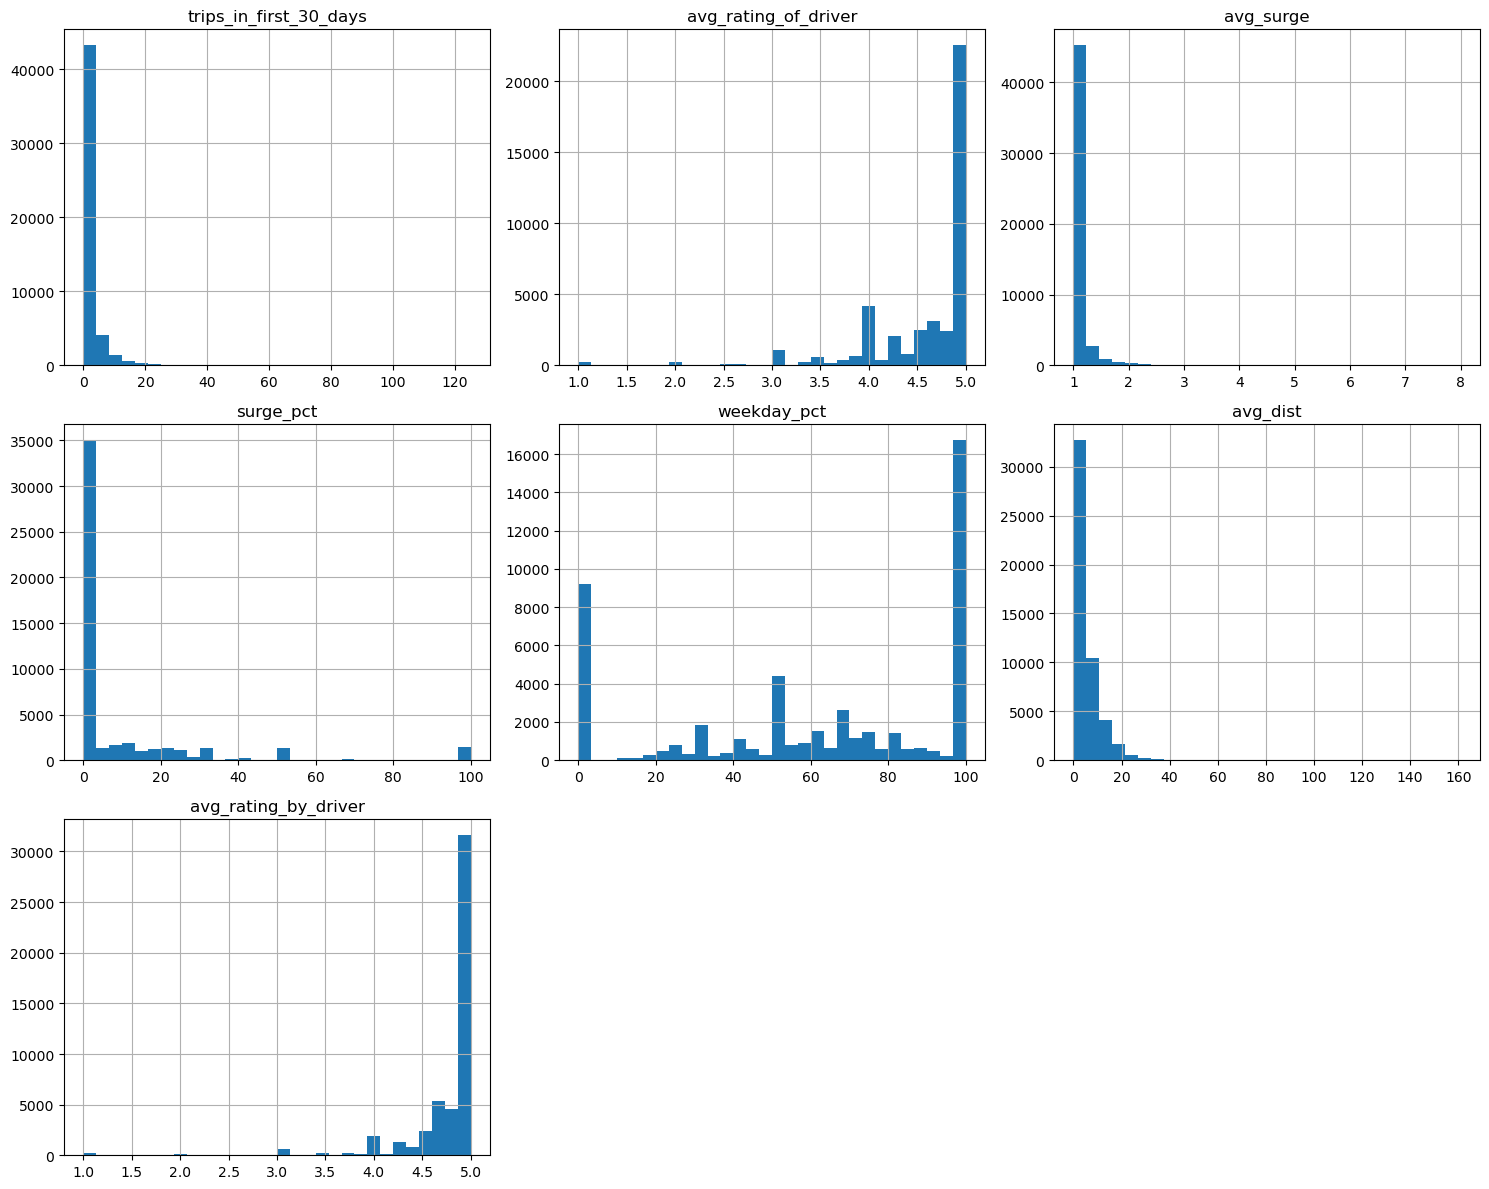

In [28]:
import matplotlib.pyplot as plt

udc_pd[numerical_cols].hist(
    bins=30,
    figsize=(15, 12)
)

plt.tight_layout()
plt.show()

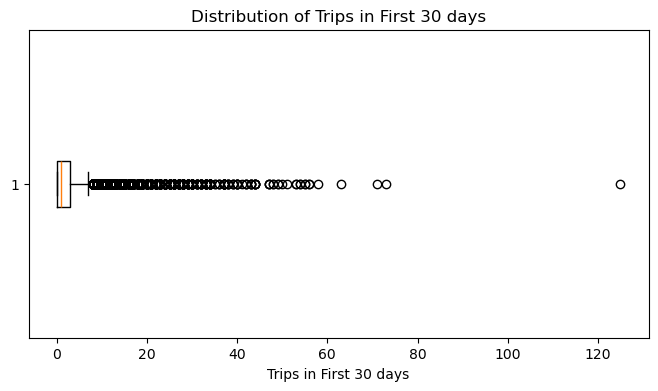

In [29]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    udc_pd["trips_in_first_30_days"].dropna(),
    vert=False
)

plt.xlabel("Trips in First 30 days")
plt.title("Distribution of Trips in First 30 days")

plt.show()

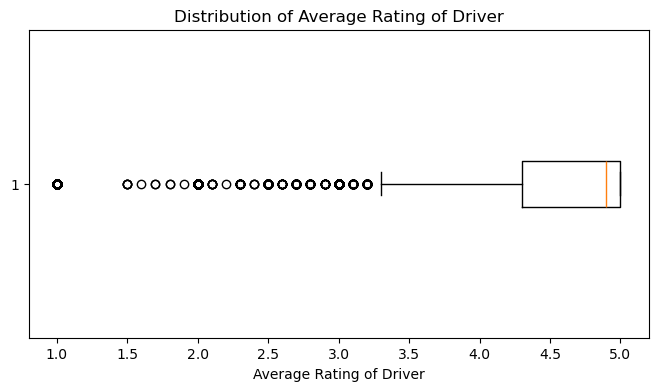

In [30]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    udc_pd["avg_rating_of_driver"].dropna(),
    vert=False
)

plt.xlabel("Average Rating of Driver")
plt.title("Distribution of Average Rating of Driver")

plt.show()

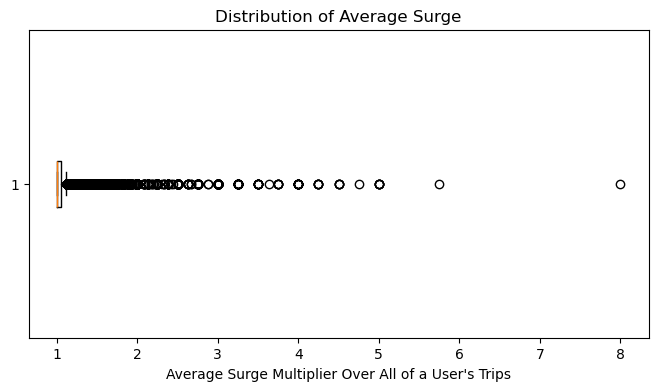

In [31]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    udc_pd["avg_surge"].dropna(),
    vert=False
)

plt.xlabel("Average Surge Multiplier Over All of a User's Trips")
plt.title("Distribution of Average Surge")

plt.show()

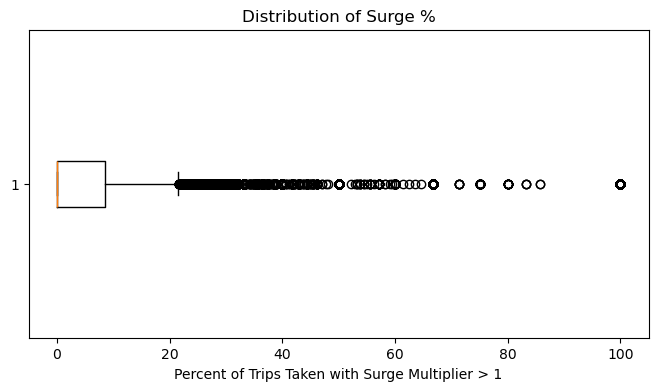

In [32]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    udc_pd["surge_pct"].dropna(),
    vert=False
)

plt.xlabel("Percent of Trips Taken with Surge Multiplier > 1")
plt.title("Distribution of Surge %")

plt.show()

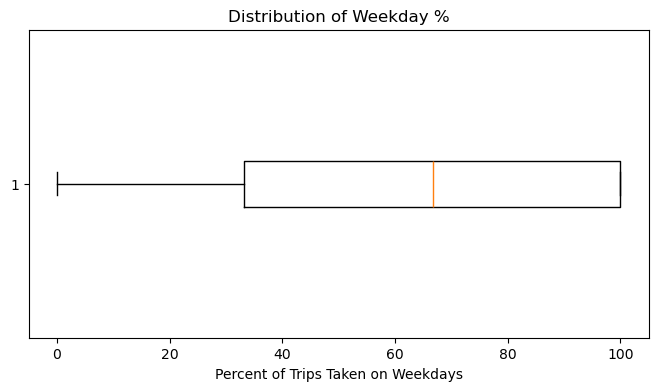

In [33]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    udc_pd["weekday_pct"].dropna(),
    vert=False
)

plt.xlabel("Percent of Trips Taken on Weekdays")
plt.title("Distribution of Weekday %")

plt.show()

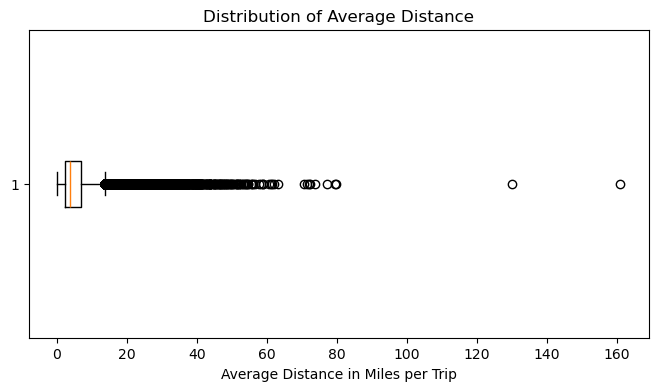

In [34]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    udc_pd["avg_dist"].dropna(),
    vert=False
)

plt.xlabel("Average Distance in Miles per Trip")
plt.title("Distribution of Average Distance")

plt.show()

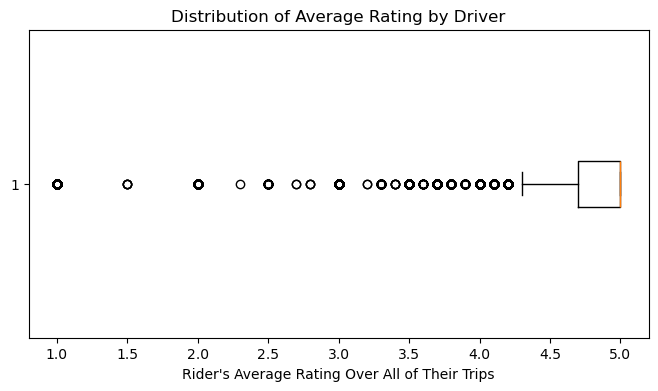

In [35]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    udc_pd["avg_rating_by_driver"].dropna(),
    vert=False
)

plt.xlabel("Rider's Average Rating Over All of Their Trips")
plt.title("Distribution of Average Rating by Driver")

plt.show()

In [36]:
udc_pd["avg_rating_by_driver"].describe()

count    49791.000000
mean         4.778123
std          0.446679
min          1.000000
25%          4.700000
50%          5.000000
75%          5.000000
max          5.000000
Name: avg_rating_by_driver, dtype: float64

In [37]:
udc_pd["avg_rating_of_driver"].describe()

count    41873.000000
mean         4.601512
std          0.617360
min          1.000000
25%          4.300000
50%          4.900000
75%          5.000000
max          5.000000
Name: avg_rating_of_driver, dtype: float64

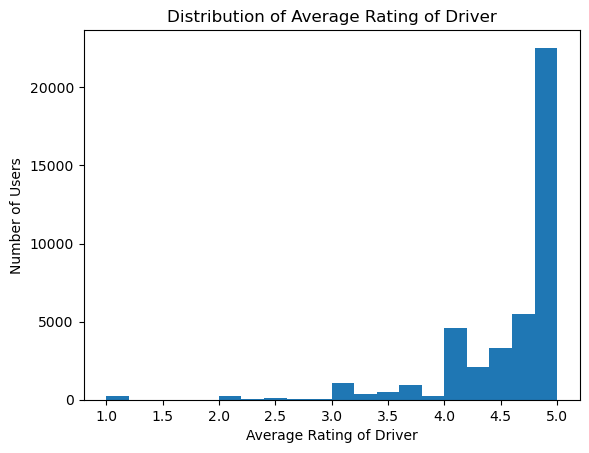

In [38]:
plt.hist(udc_pd["avg_rating_of_driver"].dropna(), bins=20)
plt.xlabel("Average Rating of Driver")
plt.ylabel("Number of Users")
plt.title("Distribution of Average Rating of Driver")
plt.show()

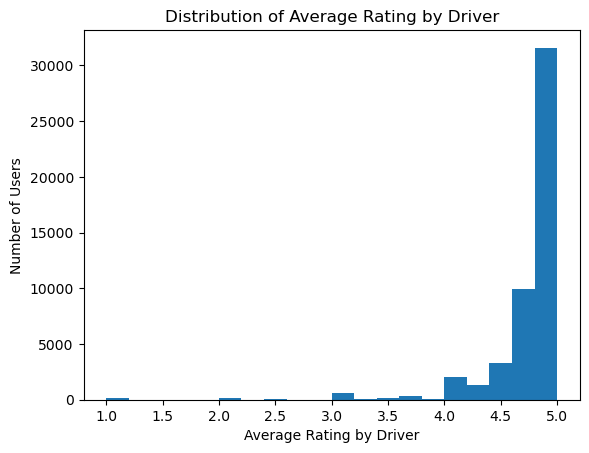

In [39]:
plt.hist(udc_pd["avg_rating_by_driver"].dropna(), bins=20)
plt.xlabel("Average Rating by Driver")
plt.ylabel("Number of Users")
plt.title("Distribution of Average Rating by Driver")
plt.show()

In [40]:
categorical_cols = [
    "city",
    "phone",
    "ultimate_black_user"
]

In [41]:
for col in categorical_cols:
    print(f"\n{col}")
    print(udc_pd[col].value_counts())
    print(udc_pd[col].value_counts(normalize=True) * 100)


city
city
Winterfell        23331
Astapor           16531
King's Landing    10130
Name: count, dtype: int64
city
Winterfell        46.669467
Astapor           33.067291
King's Landing    20.263242
Name: proportion, dtype: float64

phone
phone
iPhone     34578
Android    15018
Name: count, dtype: int64
phone
iPhone     69.719332
Android    30.280668
Name: proportion, dtype: float64

ultimate_black_user
ultimate_black_user
False    31141
True     18851
Name: count, dtype: int64
ultimate_black_user
False    62.291967
True     37.708033
Name: proportion, dtype: float64


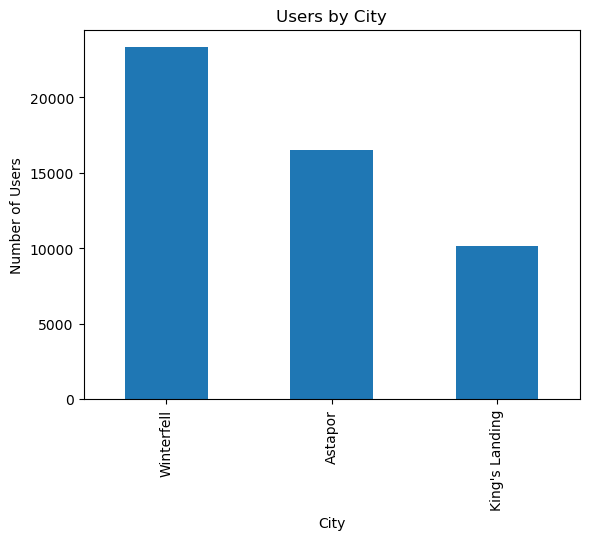

In [42]:
udc_pd["city"].value_counts().plot(kind="bar")

plt.xlabel("City")
plt.ylabel("Number of Users")
plt.title("Users by City")
plt.show()

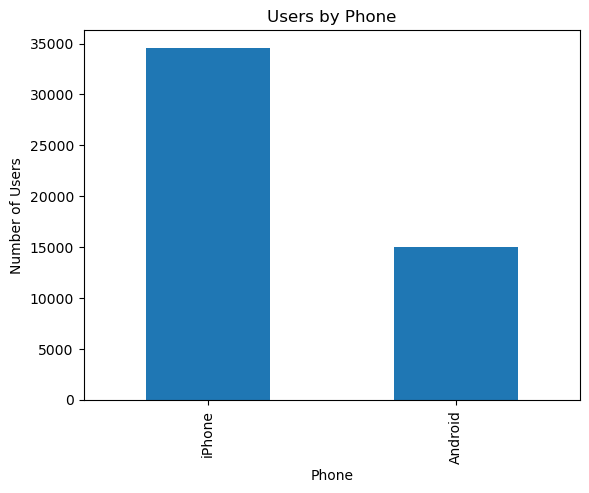

In [43]:
udc_pd["phone"].value_counts().plot(kind="bar")

plt.xlabel("Phone")
plt.ylabel("Number of Users")
plt.title("Users by Phone")
plt.show()

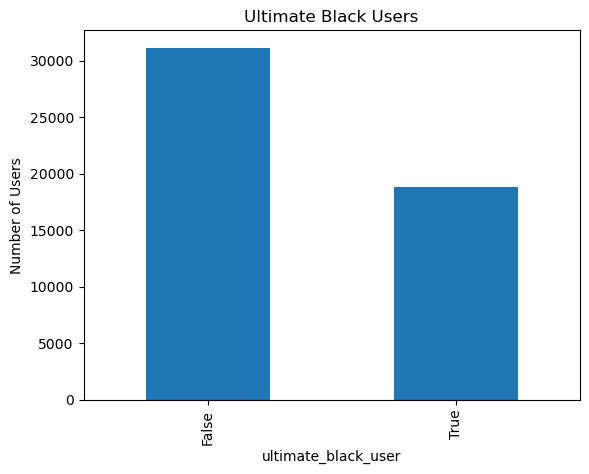

In [44]:
udc_pd["ultimate_black_user"].value_counts().plot(kind="bar")

plt.xlabel("ultimate_black_user")
plt.ylabel("Number of Users")
plt.title("Ultimate Black Users")
plt.show()

In [45]:
latest_date = udc_pd["last_trip_date"].max()
latest_date

Timestamp('2014-07-01 00:00:00')

In [46]:
retention_cutoff = latest_date - pd.Timedelta(days=30)

In [47]:
retention_cutoff

Timestamp('2014-06-01 00:00:00')

In [48]:
udc_pd["retained"] = udc_pd["last_trip_date"] >= retention_cutoff

In [49]:
udc_pd.head()

,city,trips_in_first_30_days,signup_date,avg_rating_of_driver,avg_surge,last_trip_date,phone,surge_pct,ultimate_black_user,weekday_pct,avg_dist,avg_rating_by_driver,retained
0,King's Landing,4,2014-01-25,4.7,1.10,2014-06-17,iPhone,15.4,True,46.2,3.67,5.0,True
1,Astapor,0,2014-01-29,5.0,1.00,2014-05-05,Android,0.0,False,50.0,8.26,5.0,False
2,Astapor,3,2014-01-06,4.3,1.00,2014-01-07,iPhone,0.0,False,100.0,0.77,5.0,False
3,King's Landing,9,2014-01-10,4.6,1.14,2014-06-29,iPhone,20.0,True,80.0,2.36,4.9,True
4,Winterfell,14,2014-01-27,4.4,1.19,2014-03-15,Android,11.8,False,82.4,3.13,4.9,False


In [50]:
udc_pd["retained"].value_counts()

retained
False    31188
True     18804
Name: count, dtype: int64

In [51]:
udc_pd["retained"].value_counts(normalize=True) * 100

retained
False    62.385982
True     37.614018
Name: proportion, dtype: float64

In [52]:
udc_pd.groupby("retained")[numerical_cols].mean().T

retained,False,True
trips_in_first_30_days,1.658651,3.306318
avg_rating_of_driver,4.607477,4.592930
avg_surge,1.075358,1.073809
surge_pct,8.668962,9.152797
weekday_pct,60.652969,61.389034
avg_dist,6.208739,5.114788
avg_rating_by_driver,4.787409,4.762772


In [53]:
udc_pd.groupby("retained")[numerical_cols].median().T

retained,False,True
trips_in_first_30_days,1.000,2.00
avg_rating_of_driver,5.000,4.80
avg_surge,1.000,1.00
surge_pct,0.000,0.00
weekday_pct,69.600,64.30
avg_dist,4.035,3.73
avg_rating_by_driver,5.000,4.80


In [54]:
pd.crosstab(
    udc_pd["city"],
    udc_pd["retained"],
    normalize="index"
) * 100

retained,False,True
city,,
Astapor,74.423810,25.576190
King's Landing,37.186575,62.813425
Winterfell,64.797908,35.202092


In [55]:
pd.crosstab(
    udc_pd["phone"],
    udc_pd["retained"],
    normalize="index"
) * 100

retained,False,True
phone,,
Android,79.051805,20.948195
iPhone,55.101510,44.898490


In [56]:
pd.crosstab(
    udc_pd["ultimate_black_user"],
    udc_pd["retained"],
    normalize="index"
) * 100

retained,False,True
ultimate_black_user,,
False,70.113355,29.886645
True,49.620710,50.379290


In [57]:
corr_cols = [
    "retained",
    "trips_in_first_30_days",
    "avg_rating_of_driver",
    "avg_surge",
    "surge_pct",
    "ultimate_black_user",
    "weekday_pct",
    "avg_dist",
    "avg_rating_by_driver"
]

corr = udc_pd[corr_cols].corr()
corr

,retained,trips_in_first_30_days,avg_rating_of_driver,avg_surge,surge_pct,ultimate_black_user,weekday_pct,avg_dist,avg_rating_by_driver
retained,1.000000,0.210433,-0.011590,-0.003375,0.011742,0.205028,0.009617,-0.092847,-0.026731
trips_in_first_30_days,0.210433,1.000000,-0.011272,-0.001859,0.005696,0.112220,0.050363,-0.136360,-0.039089
avg_rating_of_driver,-0.011590,-0.011272,1.000000,-0.026162,-0.003862,-0.002088,0.014680,0.034547,0.123138
avg_surge,-0.003375,-0.001859,-0.026162,1.000000,0.793578,-0.078798,-0.110124,-0.081521,0.010624
surge_pct,0.011742,0.005696,-0.003862,0.793578,1.000000,-0.106871,-0.144990,-0.104453,0.020139
ultimate_black_user,0.205028,0.112220,-0.002088,-0.078798,-0.106871,1.000000,0.036132,0.032308,0.009345
weekday_pct,0.009617,0.050363,0.014680,-0.110124,-0.144990,0.036132,1.000000,0.101607,0.020497
avg_dist,-0.092847,-0.136360,0.034547,-0.081521,-0.104453,0.032308,0.101607,1.000000,0.080583
avg_rating_by_driver,-0.026731,-0.039089,0.123138,0.010624,0.020139,0.009345,0.020497,0.080583,1.000000


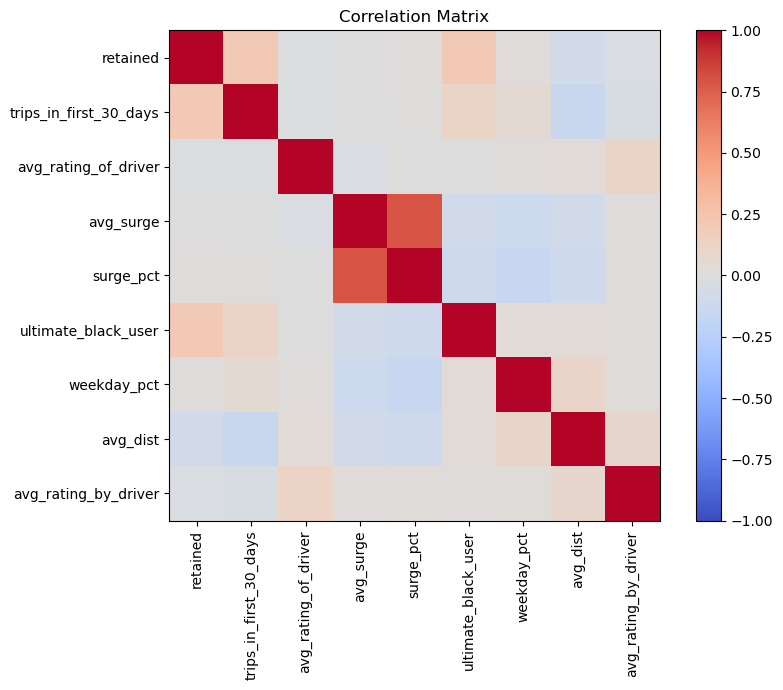

In [58]:
fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)

fig.colorbar(im)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

<b> 2. Build a predictive model to help Ultimate determine whether or not a user will be active in their 6th month on the system. Discuss why you chose your approach, what alternatives
you considered, and any concerns you have. How valid is your model? Include any key indicators of model performance </b>

<b>Answer: </b>I evaluated Logistic Regression, Decision Tree, and Random Forest classifiers using 5-fold stratified cross-validation. I considered multiple performance measures, including accuracy, precision, recall, F1, ROC-AUC, and PR-AUC. Random Forest produced the strongest overall cross-validation performance, with an accuracy of 75.7%, F1 score of 0.673, ROC-AUC of 0.823, and PR-AUC of 0.735. Therefore, Random Forest was selected as the final model.
The selected model was then trained on the complete training set and evaluated on the previously unseen test set. It achieved 75.4% accuracy, 0.674 precision, 0.668 recall, an F1 score of 0.671, ROC-AUC of 0.823, and PR-AUC of 0.738. The test results are very similar to the cross-validation results, suggesting that the model generalizes reasonably well to unseen observations and does not show an obvious loss of performance on the held-out test set.

In [59]:
y = udc_pd["retained"]

In [60]:
X = udc_pd.drop(
    columns=[
        "retained",
        "last_trip_date",
        "signup_date"
    ]
)

In [61]:
print(X.shape)
print(y.shape)

(49992, 10)
(49992,)


In [62]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [63]:
numeric_features = [
    "trips_in_first_30_days",
    "avg_rating_of_driver",
    "avg_surge",
    "surge_pct",
    "weekday_pct",
    "avg_dist",
    "avg_rating_by_driver"
]

In [64]:
categorical_features = [
    "city",
    "phone"
]

In [65]:
binary_features = [
    "ultimate_black_user"
]

In [66]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
        ("bin", "passthrough", binary_features)
    ]
)


In [67]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", logistic_model)
])

In [68]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", decision_tree_model)
])

In [69]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", random_forest_model)
])

In [70]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}


In [71]:
logistic_cv = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Logistic Regression")
print("Accuracy:", logistic_cv["test_accuracy"].mean())
print("Precision:", logistic_cv["test_precision"].mean())
print("Recall:", logistic_cv["test_recall"].mean())
print("F1:", logistic_cv["test_f1"].mean())
print("ROC-AUC:", logistic_cv["test_roc_auc"].mean())
print("PR-AUC:", logistic_cv["test_pr_auc"].mean())

Logistic Regression
Accuracy: 0.7184258153549513
Precision: 0.6707357010277488
Recall: 0.49438236708314776
F1: 0.5690946506215111
ROC-AUC: 0.7617609748613778
PR-AUC: 0.66420236302948


In [72]:
decision_tree_cv = cross_validate(
    decision_tree_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Decision Tree")
print("Accuracy:", decision_tree_cv["test_accuracy"].mean())
print("Precision:", decision_tree_cv["test_precision"].mean())
print("Recall:", decision_tree_cv["test_recall"].mean())
print("F1:", decision_tree_cv["test_f1"].mean())
print("ROC-AUC:", decision_tree_cv["test_roc_auc"].mean())
print("PR-AUC:", decision_tree_cv["test_pr_auc"].mean())

Decision Tree
Accuracy: 0.7083740868958956
Precision: 0.6127242598994895
Recall: 0.6105176270832893
F1: 0.6115446651254339
ROC-AUC: 0.6886391042441226
PR-AUC: 0.5209190552890768


In [73]:
random_forest_cv = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Random Forest")
print("Accuracy:", random_forest_cv["test_accuracy"].mean())
print("Precision:", random_forest_cv["test_precision"].mean())
print("Recall:", random_forest_cv["test_recall"].mean())
print("F1:", random_forest_cv["test_f1"].mean())
print("ROC-AUC:", random_forest_cv["test_roc_auc"].mean())
print("PR-AUC:", random_forest_cv["test_pr_auc"].mean())

Random Forest
Accuracy: 0.7568826104513378
Precision: 0.6811588767905596
Recall: 0.6648948544437608
F1: 0.672904078860197
ROC-AUC: 0.8229193304461748
PR-AUC: 0.7347679910053013


In [74]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        logistic_cv["test_accuracy"].mean(),
        decision_tree_cv["test_accuracy"].mean(),
        random_forest_cv["test_accuracy"].mean()
    ],

    "Precision": [
        
        logistic_cv["test_precision"].mean(),
        decision_tree_cv["test_precision"].mean(),
        random_forest_cv["test_precision"].mean()
    ],

    "Recall": [
        
        logistic_cv["test_recall"].mean(),
        decision_tree_cv["test_recall"].mean(),
        random_forest_cv["test_recall"].mean()
    ],

    "F1": [
        
        logistic_cv["test_f1"].mean(),
        decision_tree_cv["test_f1"].mean(),
        random_forest_cv["test_f1"].mean()
    ],

    "ROC_AUC": [
        
        logistic_cv["test_roc_auc"].mean(),
        decision_tree_cv["test_roc_auc"].mean(),
        random_forest_cv["test_roc_auc"].mean()
    ],

    "PR_AUC": [
        
        logistic_cv["test_pr_auc"].mean(),
        decision_tree_cv["test_pr_auc"].mean(),
        random_forest_cv["test_pr_auc"].mean()
    ]
})

results.sort_values(by="PR_AUC", ascending=False).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
2,Random Forest,0.757,0.681,0.665,0.673,0.823,0.735
0,Logistic Regression,0.718,0.671,0.494,0.569,0.762,0.664
1,Decision Tree,0.708,0.613,0.611,0.612,0.689,0.521


In [75]:
# Train final Random Forest model
random_forest_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['trips_in_first_30_days',
                                                   'avg_rating_of_driver',
                                                   'avg_surge', 'surge_pct',
                                                   'weekday_pct', 'avg_dist',
                                                   'avg_rating_by_driver']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['city', 'phone']),
                                                 ('bin', 'passthrough',
                                                  ['ultimate_black_user'])])),
                ('classifier',
                 RandomForestClassifier(n_estimators=200, random_state=42))])

In [76]:
# Make predictions on untouched test set
y_pred = random_forest_pipeline.predict(X_test)

# Predicted probabilities for retained=True
y_prob = random_forest_pipeline.predict_proba(X_test)[:, 1]

In [77]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("Random Forest Test Results")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))

Random Forest Test Results
Accuracy: 0.7538753875387538
Precision: 0.6743562231759657
Recall: 0.6684392448816804
F1: 0.671384697556416
ROC-AUC: 0.8229885719853588
PR-AUC: 0.7381121340230716


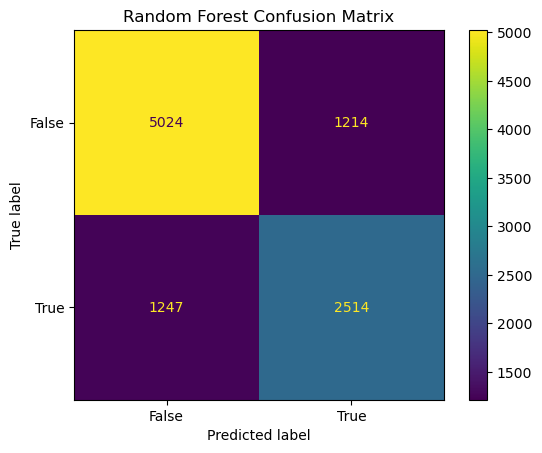

In [78]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title("Random Forest Confusion Matrix")
plt.show()

In [79]:
feature_names = (
    random_forest_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    random_forest_pipeline
    .named_steps["classifier"]
    .feature_importances_
)

In [80]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Feature,Importance
5,num__avg_dist,0.300540
4,num__weekday_pct,0.133562
6,num__avg_rating_by_driver,0.114504
0,num__trips_in_first_30_days,0.082357
1,num__avg_rating_of_driver,0.079622
3,num__surge_pct,0.073758
2,num__avg_surge,0.070407
8,cat__city_King's Landing,0.046523
13,bin__ultimate_black_user,0.030768
11,cat__phone_iPhone,0.019821


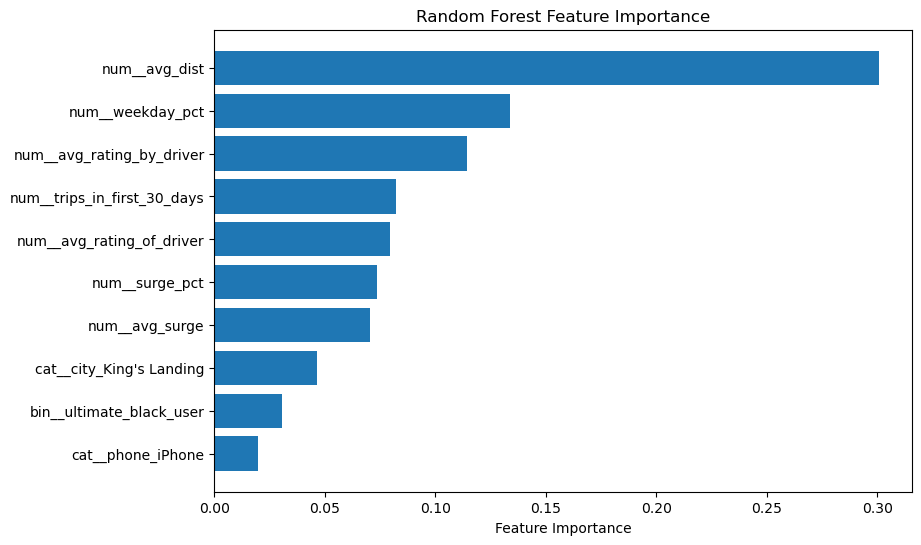

In [81]:
top_features = feature_importance.head(10)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()
plt.show()

<b>3.  Briefly discuss how Ultimate might leverage the insights gained from the model to
improve its long term rider retention (again, a few sentences will suffice)</b>

<b>Answer: </b> Ultimate could use the predictive model to identify riders who are at higher risk of becoming inactive and target them with retention efforts such as personalized promotions or incentives. Since early trip activity was associated with retention, Ultimate could encourage new users to take more trips during their first 30 days through introductory promotions or rewards. The model also identified factors such as average trip distance, weekday usage, city, and Ultimate Black usage as useful predictors, which could help Ultimate segment users and tailor retention strategies to different rider behaviors. However, these factors should be treated as predictive associations rather than causes of retention, and Ultimate should use controlled experiments to determine whether specific interventions actually improve long-term retention.